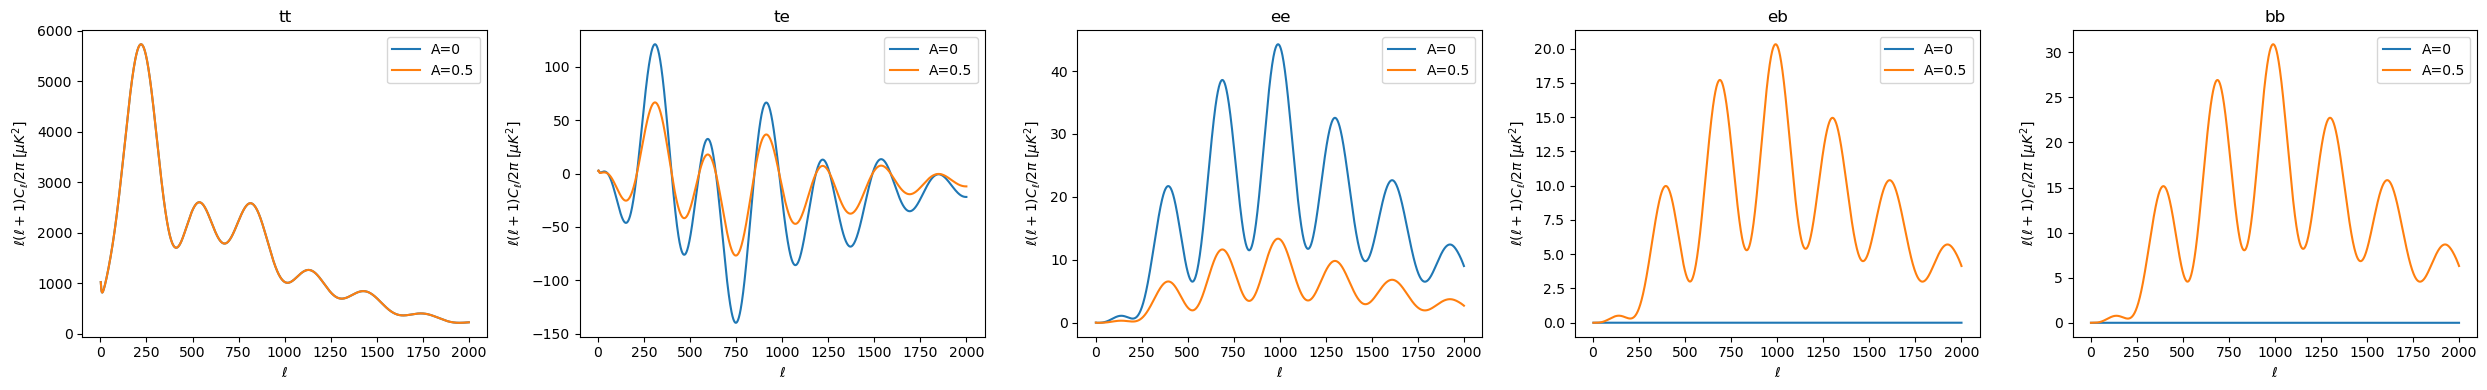

In [92]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class


A_VALUES = [0.0, .5]        
L = 1/1509 # this is 1/tau_z=7.7 in 1/Mpc                   
LMAX = 2000


base = {
    'output': 'tCl,pCl',
    'l_max_scalars': LMAX,
    'lensing': 'no',            
    'hierarchy': 'tam',      
    'birefringence_L': L,
}

T_CMB = 2.7255e6  # uK
results_tam = {}

for A in A_VALUES:
    cosmo = Class()
    cosmo.set(base)
    cosmo.set({'birefringence_A': A})
    cosmo.compute()
    cl = cosmo.raw_cl(LMAX)
    results_tam[A] = cl
    cosmo.struct_cleanup()
    cosmo.empty()

ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2   

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, key in zip(axes, ['tt','te','ee','eb', 'bb', 'tb']): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    for A, cl in results_tam.items(): #results_tam holds all the Cl arrays for different A values, so we loop through them
        y = fac*cl[key]
        ax.plot(ell[2:], y[2:], label=f"A={A:g}")
    ax.set_xscale('linear')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
    ax.legend()
plt.tight_layout()
plt.show()

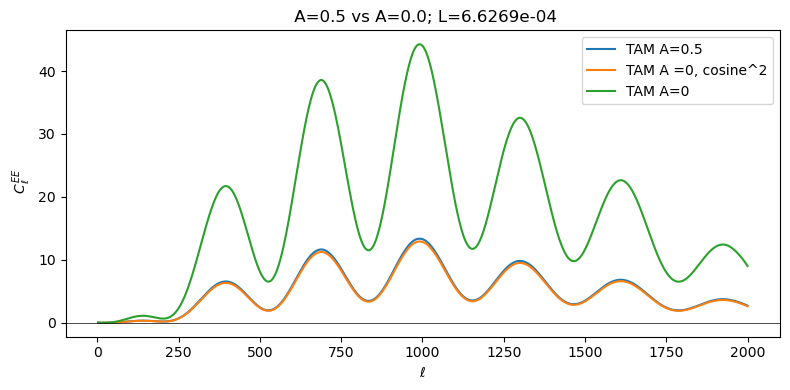

In [86]:
cl_ee_cos = np.cos(2*A_VALUES[1])*np.cos(2*A_VALUES[1])*results_tam[A_VALUES[0]]['ee']
ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2 

plt.figure(figsize=(8, 4))
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[1]]['ee'][2:], label = 'TAM A=0.5')
plt.plot(ell[2:], fac[2:]*cl_ee_cos[2:], label= 'TAM A =0, cosine^2')
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[0]]['ee'][2:], label= 'TAM A=0')
plt.xscale('linear')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ C_\ell^{EE}$')
plt.title(f" A={A_VALUES[1]} vs A={A_VALUES[0]}; L={L:.4e}")
plt.legend()
plt.tight_layout()
plt.show()

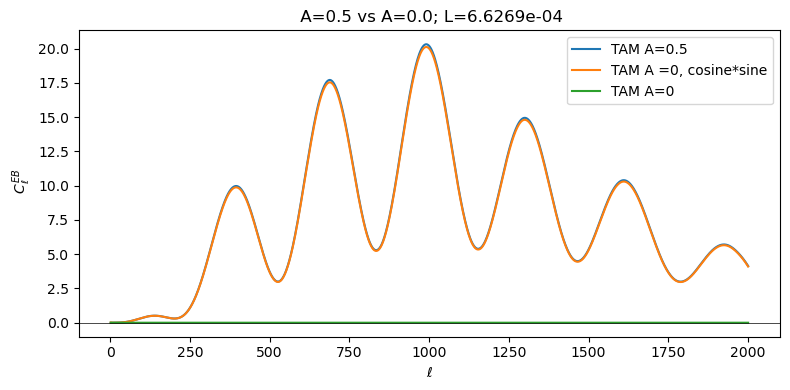

In [88]:
cl_eb_cos = np.sin(2*A_VALUES[1])*np.cos(2*A_VALUES[1])*results_tam[A_VALUES[0]]['ee']
ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2 

plt.figure(figsize=(8, 4))
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[1]]['eb'][2:], label = 'TAM A=0.5')
plt.plot(ell[2:], fac[2:]*cl_eb_cos[2:], label= 'TAM A =0, cosine*sine')
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[0]]['eb'][2:], label= 'TAM A=0')
plt.xscale('linear')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ C_\ell^{EB}$')
plt.title(f" A={A_VALUES[1]} vs A={A_VALUES[0]}; L={L:.4e}")
plt.legend()
plt.tight_layout()
plt.show()

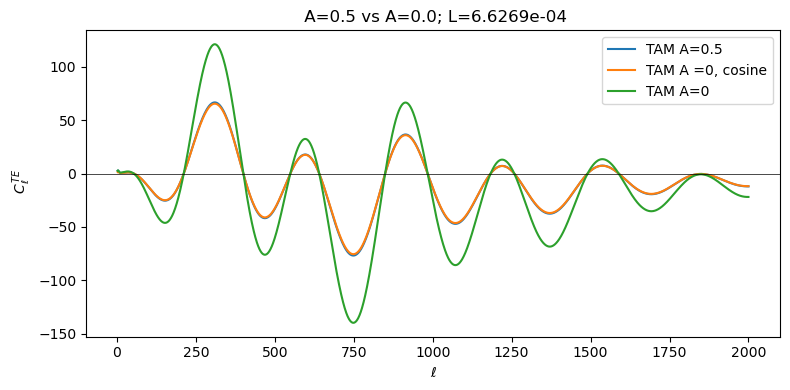

In [94]:
cl_te_cos = np.cos(2*A_VALUES[1])*results_tam[A_VALUES[0]]['te']
ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2 

plt.figure(figsize=(8, 4))
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[1]]['te'][2:], label = 'TAM A=0.5')
plt.plot(ell[2:], fac[2:]*cl_te_cos[2:], label= 'TAM A =0, cosine')
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[0]]['te'][2:], label= 'TAM A=0')
plt.xscale('linear')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ C_\ell^{TE}$')
plt.title(f" A={A_VALUES[1]} vs A={A_VALUES[0]}; L={L:.4e}")
plt.legend()
plt.tight_layout()
plt.show()

In [75]:
diff_tt = results_tam[A_VALUES[1]]['tt'] - results_tam[A_VALUES[0]]['tt']
diff_te = results_tam[A_VALUES[1]]['te'] - results_tam[A_VALUES[0]]['te']
diff_ee = results_tam[A_VALUES[1]]['ee'] - results_tam[A_VALUES[0]]['ee']
print(f"Difference in TT Cls between A={A_VALUES[1]} and A={A_VALUES[0]}: {diff_tt}")
print("max difference in TT Cls:", np.max(np.abs(diff_tt)))
print(f"Difference in TE Cls between A={A_VALUES[1]} and A={A_VALUES[0]}: {diff_te}")
print("max difference in TE Cls:", np.max(np.abs(diff_te)))
print(f"Difference in EE Cls between A={A_VALUES[1]} and A={A_VALUES[0]}: {diff_ee}")
print("max difference in EE Cls:", np.max(np.abs(diff_ee)))
#plt.legend()
#plt.tight_layout()
#plt.show()

Difference in TT Cls between A=0.5 and A=0.0: [ 0.00000000e+00  0.00000000e+00 -5.92145656e-17 ... -5.43937667e-23
 -5.96416133e-23 -6.50001194e-23]
max difference in TT Cls: 5.92145655990866e-17
Difference in TE Cls between A=0.5 and A=0.0: [ 0.00000000e+00  0.00000000e+00 -5.40109021e-15 ...  2.09612502e-18
  2.09379609e-18  2.09112361e-18]
max difference in TE Cls: 5.401090208619858e-15
Difference in EE Cls between A=0.5 and A=0.0: [ 0.00000000e+00  0.00000000e+00 -1.25163222e-16 ... -1.35818057e-18
 -1.34494499e-18 -1.33156801e-18]
max difference in EE Cls: 1.251632220262532e-16


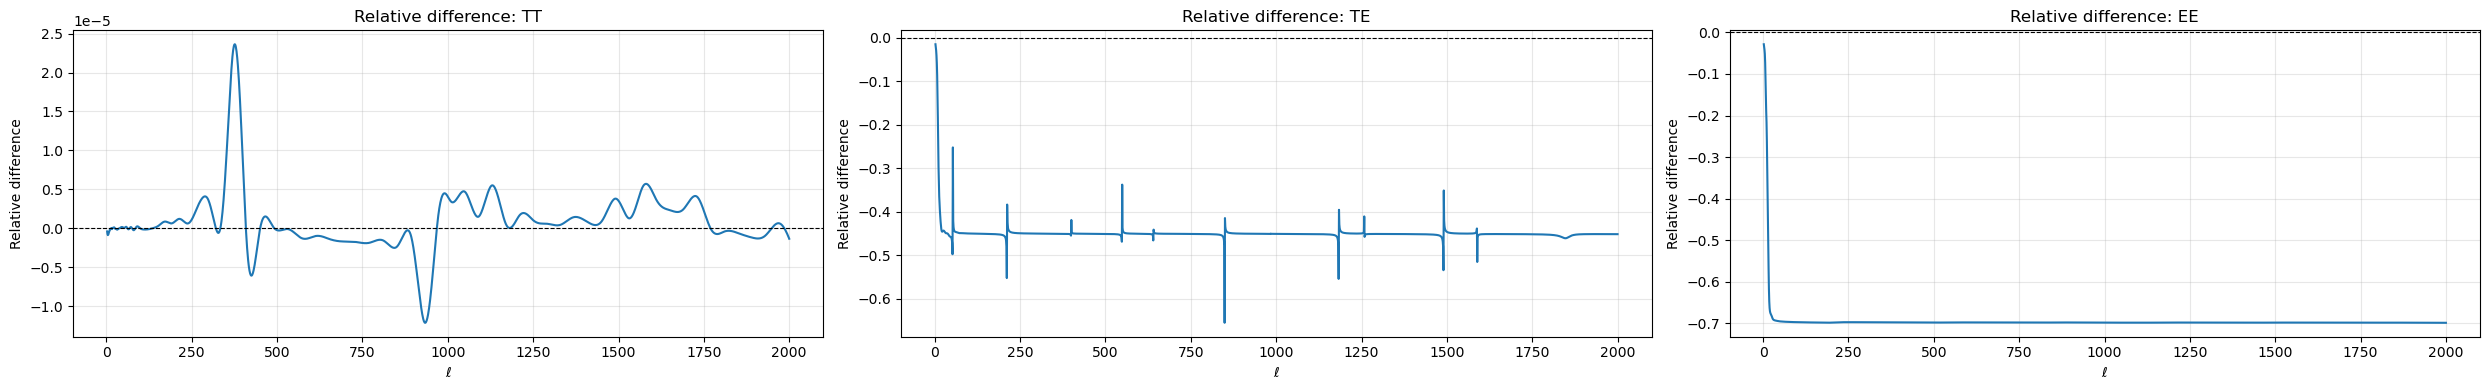

In [76]:
ref_tt = results_tam[A_VALUES[0]]['tt']
rel_tt = diff_tt[2:] / ref_tt[2:]

ref_te = results_tam[A_VALUES[0]]['te']
rel_te = diff_te[2:] / ref_te[2:]

ref_ee = results_tam[A_VALUES[0]]['ee']
rel_ee = diff_ee[2:] / ref_ee[2:]

#plot ell vs rel_tt, rel_te, rel_ee in a single figure with 3 subplots:

fig, axes = plt.subplots(1, 3, figsize=(25, 4))

for ax, rel, label in zip(
    axes,
    (rel_tt, rel_te, rel_ee),
    ("TT", "TE", "EE"),
):
    ax.plot(ell[2:], rel)
    ax.set_title(f"Relative difference: {label}")
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel("Relative difference")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [77]:
print(np.max(np.abs(rel_tt)))
print(np.max(np.abs(rel_te)))
print(np.max(np.abs(rel_ee)))

2.3632840100870844e-05
0.6548035722389054
0.6985017247621043


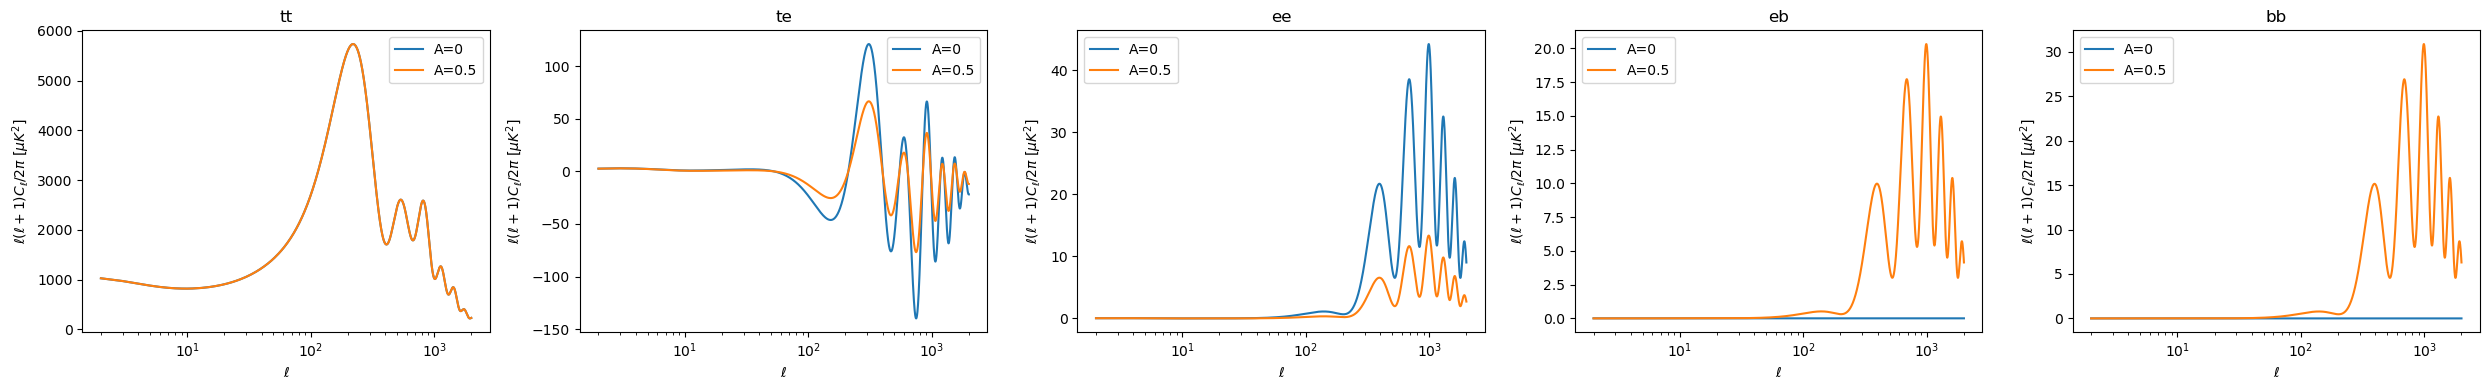

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class


A_VALUES = [0.0, 0.5]        
L = 1/1509 # this is 1/tau_z=7.7 in 1/Mpc                   
LMAX = 2000


base = {
    'output': 'tCl,pCl',
    'l_max_scalars': LMAX,
    'lensing': 'no',            
    'hierarchy': 'optimal',      
    'birefringence_L': L,
}

T_CMB = 2.7255e6  # uK
results_optimal = {}

for A in A_VALUES:
    cosmo = Class()
    cosmo.set(base)
    cosmo.set({'birefringence_A': A})
    cosmo.compute()
    cl = cosmo.raw_cl(LMAX)
    results_optimal[A] = cl
    cosmo.struct_cleanup()
    cosmo.empty()

ell = results_optimal[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2   

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, key in zip(axes, ['tt','te','ee','eb', 'bb', 'tb']): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    for A, cl in results_optimal.items(): #results_optimal holds all the Cl arrays for different A values, so we loop through them
        y = fac*cl[key]
        ax.plot(ell[2:], y[2:], label=f"A={A:g}")
    ax.set_xscale('log')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
    ax.legend()
plt.tight_layout()
plt.show()

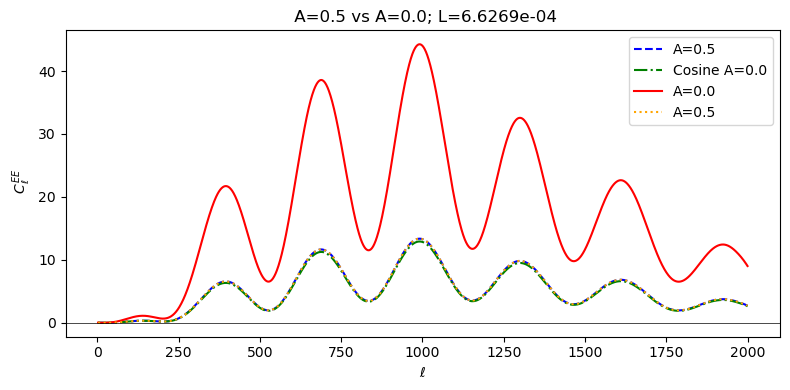

In [79]:
cl_ee_cos = np.cos(2*A_VALUES[1])*np.cos(2*A_VALUES[1])*results_tam[A_VALUES[0]]['ee']
cl_ee_cos_opt = np.cos(2*A_VALUES[1])*results_optimal[A_VALUES[0]]['ee']
ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2 

plt.figure(figsize=(8, 4))
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[1]]['ee'][2:], color='blue', linestyle= '--',  label=f"A={A_VALUES[1]}")
plt.plot(ell[2:], fac[2:]*cl_ee_cos[2:], color='green', linestyle= '-.', label=f"Cosine A={A_VALUES[0]}")
#plt.plot(ell[2:], fac[2:]*cl_ee_cos_opt[2:], color='orange', linestyle='--', label='Optimal Cosine')
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[0]]['ee'][2:], color='red', label=f"A={A_VALUES[0]}")
plt.plot(ell[2:], fac[2:]*results_optimal[A_VALUES[1]]['ee'][2:], color= 'orange', linestyle='dotted', label=f"A={A_VALUES[1]}")
plt.xscale('linear')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ C_\ell^{EE}$')
plt.title(f" A={A_VALUES[1]} vs A={A_VALUES[0]}; L={L:.4e}")
plt.legend()
plt.tight_layout()
plt.show()

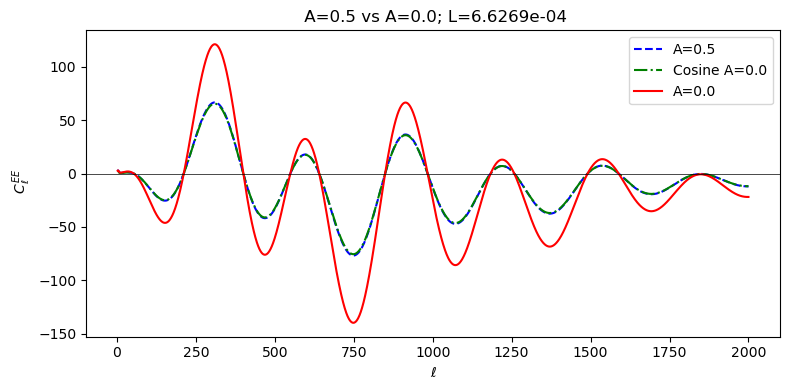

In [80]:
cl_te_cos = np.cos(2*A_VALUES[1])*results_tam[A_VALUES[0]]['te']
cl_te_cos_opt = np.cos(2*A_VALUES[1])*results_optimal[A_VALUES[0]]['te']
ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2 

plt.figure(figsize=(8, 4))
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[1]]['te'][2:], color='blue', linestyle= '--',  label=f"A={A_VALUES[1]}")
plt.plot(ell[2:], fac[2:]*cl_te_cos[2:], color='green', linestyle= '-.', label=f"Cosine A={A_VALUES[0]}")
#plt.plot(ell[2:], fac[2:]*cl_te_cos_opt[2:], color='grey', linestyle='--', label='Optimal Cosine')
plt.plot(ell[2:], fac[2:]*results_tam[A_VALUES[0]]['te'][2:], color='red', label=f"A={A_VALUES[0]}")
#plt.plot(ell[2:], fac[2:]*results_optimal[A_VALUES[1]]['te'][2:], color= 'orange', linestyle='dotted', label=f"A={A_VALUES[1]}")
plt.xscale('linear')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ C_\ell^{EE}$')
plt.title(f" A={A_VALUES[1]} vs A={A_VALUES[0]}; L={L:.4e}")
plt.legend()
plt.tight_layout()
plt.show()

In [81]:
print(f"Max difference in TT Cls between optimal and tam: {(np.max(np.abs(results_optimal[A_VALUES[1]]['tt'] - results_tam[A_VALUES[1]]['tt'])))/np.max(np.abs(results_tam[A_VALUES[1]]['tt']))}")
print(f"Max difference in EE Cls between optimal and tam: {(np.max(np.abs(results_optimal[A_VALUES[1]]['ee'] - results_tam[A_VALUES[1]]['ee'])))/np.max(np.abs(results_tam[A_VALUES[1]]['ee']))}")
print(f"Max difference in BB Cls between optimal and tam: {(np.max(np.abs(results_optimal[A_VALUES[1]]['bb'] - results_tam[A_VALUES[1]]['bb'])))/np.max(np.abs(results_tam[A_VALUES[1]]['bb']))}")  
print(f"Max difference in EB Cls between optimal and tam: {(np.max(np.abs(results_optimal[A_VALUES[1]]['eb'] - results_tam[A_VALUES[1]]['eb'])))/np.max(np.abs(results_tam[A_VALUES[1]]['eb']))}")
print(f"Max difference in TE Cls between optimal and tam: {(np.max(np.abs(results_optimal[A_VALUES[1]]['te'] - results_tam[A_VALUES[1]]['te'])))/np.max(np.abs(results_tam[A_VALUES[1]]['te']))}")

Max difference in TT Cls between optimal and tam: 4.2679523125730425e-07
Max difference in EE Cls between optimal and tam: 0.0006872651446974349
Max difference in BB Cls between optimal and tam: 0.00037934651279380684
Max difference in EB Cls between optimal and tam: 0.0005771325199257721
Max difference in TE Cls between optimal and tam: 0.00022954373719747193


/tmp/ipykernel_7008/1602180318.py:1: RuntimeWarning: invalid value encountered in divide
  delta_tt = (results_optimal[A_VALUES[1]]['tt'] - results_tam[A_VALUES[1]]['tt'])/results_tam[A_VALUES[1]]['tt']
/tmp/ipykernel_7008/1602180318.py:2: RuntimeWarning: invalid value encountered in divide
  delta_ee = (results_optimal[A_VALUES[1]]['ee'] - results_tam[A_VALUES[1]]['ee'])/results_tam[A_VALUES[1]]['ee']
/tmp/ipykernel_7008/1602180318.py:3: RuntimeWarning: invalid value encountered in divide
  delta_bb = (results_optimal[A_VALUES[1]]['bb'] - results_tam[A_VALUES[1]]['bb'])/results_tam[A_VALUES[1]]['bb']
/tmp/ipykernel_7008/1602180318.py:4: RuntimeWarning: invalid value encountered in divide
  delta_eb = (results_optimal[A_VALUES[1]]['eb'] - results_tam[A_VALUES[1]]['eb'])/results_tam[A_VALUES[1]]['eb']
/tmp/ipykernel_7008/1602180318.py:5: RuntimeWarning: invalid value encountered in divide
  delta_te = (results_optimal[A_VALUES[1]]['te'] - results_tam[A_VALUES[1]]['te'])/results_tam[A_VA

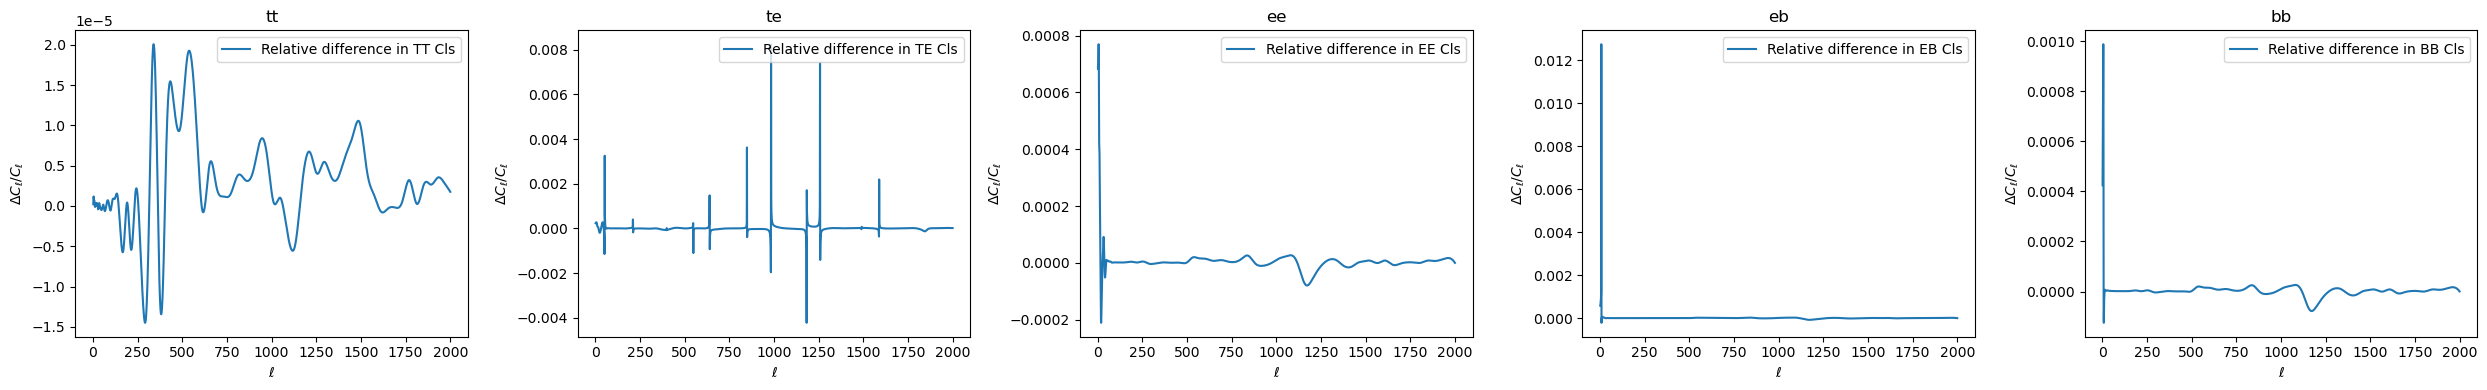

In [82]:
delta_tt = (results_optimal[A_VALUES[1]]['tt'] - results_tam[A_VALUES[1]]['tt'])/results_tam[A_VALUES[1]]['tt']
delta_ee = (results_optimal[A_VALUES[1]]['ee'] - results_tam[A_VALUES[1]]['ee'])/results_tam[A_VALUES[1]]['ee']
delta_bb = (results_optimal[A_VALUES[1]]['bb'] - results_tam[A_VALUES[1]]['bb'])/results_tam[A_VALUES[1]]['bb']
delta_eb = (results_optimal[A_VALUES[1]]['eb'] - results_tam[A_VALUES[1]]['eb'])/results_tam[A_VALUES[1]]['eb']
delta_te = (results_optimal[A_VALUES[1]]['te'] - results_tam[A_VALUES[1]]['te'])/results_tam[A_VALUES[1]]['te']

delta_dict = {'tt': delta_tt, 'ee': delta_ee, 'bb': delta_bb, 'eb': delta_eb, 'te': delta_te}

ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, key in zip(axes, ['tt','te','ee','eb', 'bb', 'tb']): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    y = delta_dict[key]
    ax.plot(ell[2:], y[2:], label=f"Relative difference in {key.upper()} Cls")
    ax.set_xscale('linear')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\Delta C_{\ell} / C_{\ell}$')
    #ax.set_xlim(0, 20)
    ax.legend()
plt.tight_layout()
plt.show()

In [83]:
no_inf_delta_tt = delta_tt[np.isfinite(delta_tt)]
no_inf_delta_te = delta_te[np.isfinite(delta_te)]
no_inf_delta_ee = delta_ee[np.isfinite(delta_ee)]
no_inf_delta_bb = delta_bb[np.isfinite(delta_bb)]
no_inf_delta_eb = delta_eb[np.isfinite(delta_eb)]

print(f"max delta_tt: {np.max(np.abs(no_inf_delta_tt))}")
print(f"max delta_te: {np.max(np.abs(no_inf_delta_te))}")
print(f"max delta_ee: {np.max(np.abs(no_inf_delta_ee))}")
print(f"max delta_bb: {np.max(np.abs(no_inf_delta_bb))}")
print(f"max delta_eb: {np.max(np.abs(no_inf_delta_eb))}")

max delta_tt: 2.0060052162153023e-05
max delta_te: 0.008241419150202045
max delta_ee: 0.0007697839325739193
max delta_bb: 0.0009873108692541395
max delta_eb: 0.012752171189388942
